In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

df = pd.read_csv("../data/clean.csv")

print("Размер датасета:", df.shape)
print("Пропуски:", df.isna().sum().sum())
print("Дубликаты:", df.duplicated().sum())

display(df.head())


Размер датасета: (649, 33)
Пропуски: 0
Дубликаты: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [ ]:
df["at_risk"] = (df["G3"] < 10).astype(int)

print("Размер датасета:", df.shape)
print("\nКоличество по классам:")
print(df["at_risk"].value_counts().sort_index())
print("\nДоли классов:")
print(df["at_risk"].value_counts(normalize=True).sort_index().round(4))

X = df.drop(columns=["G3", "at_risk"])
y = df["at_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTrain:", X_train.shape)
print("Test:", X_test.shape)
print("\nДоля группы риска:")
print("Train:", round(y_train.mean(), 4))
print("Test:", round(y_test.mean(), 4))


Размер датасета: (649, 34)

Количество по классам:
at_risk
0    549
1    100
Name: count, dtype: int64

Доли классов:
at_risk
0    0.8459
1    0.1541
Name: proportion, dtype: float64

Train: (486, 32)
Test: (163, 32)

Доля группы риска:
Train: 0.1543
Test: 0.1534


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
df = pd.read_csv("../data/clean.csv")
df["at_risk"] = (df["G3"] < 10).astype(int)
X = df.drop(columns=["G3", "at_risk"])
y = df["at_risk"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

prep = make_column_transformer(
    (
        make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        ),
        num_cols
    ),
    (
        make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore")
        ),
        cat_cols
    )
)
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": LogisticRegression(max_iter=2000)
}
results = []
for name, clf in models.items():
    model = make_pipeline(prep, clf)

    cv_f1 = cross_val_score(
        model, X_train, y_train,
        cv=5, scoring="f1"
    ).mean()

    cv_auc = cross_val_score(
        model, X_train, y_train,
        cv=5, scoring="roc_auc"
    ).mean()

    cv_accuracy = cross_val_score(
        model, X_train, y_train,
        cv=5, scoring="accuracy"
    ).mean()
    results.append({
        "model": name,
        "cv_accuracy": cv_accuracy,
        "cv_f1": cv_f1,
        "cv_roc_auc": cv_auc
    })
results_df = pd.DataFrame(results)
display(results_df.round(4))


,model,cv_accuracy,cv_f1,cv_roc_auc
0,Dummy,0.8457,0.000,0.5000
1,LogisticRegression,0.9198,0.722,0.9663


Матрица ошибок:
[[131   7]
 [  7  18]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9493    0.9493    0.9493       138
           1     0.7200    0.7200    0.7200        25

    accuracy                         0.9141       163
   macro avg     0.8346    0.8346    0.8346       163
weighted avg     0.9141    0.9141    0.9141       163

TN: 131 FP: 7 FN: 7 TP: 18
Precision: 0.72
Recall: 0.72
F1: 0.72


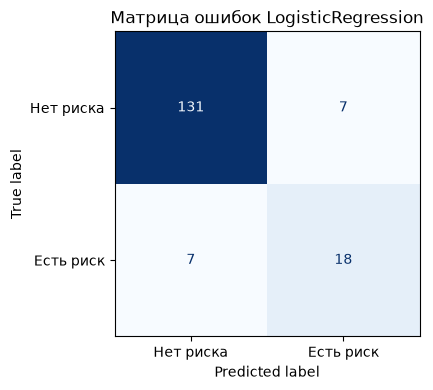

In [5]:

from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

model = make_pipeline(
    prep,
    LogisticRegression(max_iter=2000)
)
model.fit(X_train, y_train)

pred = model.predict(X_test)

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()

print("Матрица ошибок:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, pred, digits=4))

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print("TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))

fig, ax = plt.subplots(figsize=(7, 4))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Нет риска", "Есть риск"]
).plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Матрица ошибок LogisticRegression")
plt.tight_layout()

# Сохраняем график для Markdown
ROOT = Path.cwd()
if not (ROOT / "data" / "clean.csv").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIG_DIR / "lab9_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
